<a href="https://colab.research.google.com/github/Lujan-84/TPI-Analisis-de-Datos/blob/main/notebooks/TPI_Analisis_de_Datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TRABAJO PRÁCTICO INTEGRADOR
## Introducción al Análisis de Datos

# Customer Churn
### Análisis exploratorio de datos e identificación de factores asociados al abandono de clientes en el sector de telecomunicaciones.

**Dataset:** Telco Customer Churn (Kaggle)

**Integrantes:**
- Jazmín Luque
- Thiago Martínez
- Luján Miguel
- Edelmar Ricaldez

## 0. Importación de librerías y configuracio general

En esta sección importamos las principales bibliotecas de Python que utilizaremos a lo largo del análisis y establecemos configuraciones generales para facilitar la manipulación, el análisis estadístico y la visualización de los datos.

In [ ]:

# Librerías principales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from IPython.display import display

# Configuración general

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)

# Versiones de las librerías
print(
    "pandas:", pd.__version__,
    "| numpy:", np.__version__,
    "| seaborn:", sns.__version__
)


pandas: 2.2.3 | numpy: 2.4.6 | seaborn: 0.13.2


## Carga del conjunto de datos

En esta sección obtenemos el conjunto de datos **Telco Customer Churn** desde Kaggle utilizando la biblioteca KaggleHub. Los datos originales se almacenan en un DataFrame y se genera una copia de trabajo para realizar las tareas de exploración, limpieza, transformación y análisis, preservando los datos originales sin modificaciones.

In [ ]:

# Instalamos la dependencia necesaria
!pip install -q kagglehub[pandas-datasets]

# Importamos KaggleHub
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Archivo que queremos cargar
file_path = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

# Cargamos los datos originales desde Kaggle
df_raw = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "blastchar/telco-customer-churn",
    file_path
)

# Creamos una copia para trabajar
df = df_raw.copy()

# Información inicial
print("Dimensiones del dataset:", df.shape)
display(df.head())


Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Dimensiones del dataset: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# 1. Fundamentos

### 1.1 Contexto y problema de negocio

En el sector de las telecomunicaciones, las empresas ofrecen distintos servicios a sus clientes, como telefonía, conexión a internet y prestaciones adicionales. Sin embargo, no todos los usuarios mantienen su relación comercial a largo plazo: algunos deciden finalizar su contrato y contratar los servicios de otra compañía. Este comportamiento se conoce como *churn* o abandono de clientes.

La pérdida de usuarios representa un desafío para las empresas, ya que afecta sus ingresos y puede incrementar los costos asociados a la captación de nuevos clientes. Por este motivo, resulta importante comprender qué factores pueden influir en la decisión de abandonar el servicio.

A partir del análisis de la información disponible, se busca identificar patrones de comportamiento y características que permitan reconocer a los clientes con mayor probabilidad de cancelar su servicio. Esto podría facilitar la implementación de estrategias de fidelización y retención.

**Pregunta de negocio:** ¿Qué características de los clientes, los servicios contratados y las condiciones de contratación se relacionan con el abandono? ¿Podemos utilizar esta información para identificar anticipadamente a los clientes que presentan mayor riesgo de churn?

### 1.2 Variable objetivo

Para este análisis se utilizará la variable **`Churn`** como variable objetivo. Esta permite identificar si un cliente abandonó la empresa (`Yes`) o si continúa utilizando sus servicios (`No`).

Se trata de una variable cualitativa nominal binaria, ya que contempla dos categorías sin un orden determinado. Su análisis permitirá estudiar la distribución del abandono e identificar posibles relaciones con otras características de los clientes y los servicios contratados.

### 1.3. Hipótesis analíticas
A partir del problema de negocio planteado, se proponen las siguientes hipótesis para orientar el análisis exploratorio y evaluar qué características podrían estar relacionadas con el abandono de clientes:

H1 (Perfil demográfico — Adultos mayores): Los clientes clasificados como adultos mayores (SeniorCitizen = 1) presentan una tasa de cancelación significativamente mayor en comparación con los usuarios más jóvenes, influenciados por la adopción de tipos de contrato a corto plazo o métodos de pago manuales.
H2 (Modalidad contractual — Plazo de permanencia): Los clientes con contratos mensuales (Month-to-month) registran una tasa de abandono notablemente superior frente a quienes poseen contratos a largo plazo (anuales o bianuales), debido a la ausencia de un compromiso de permanencia que retenga al usuario.


Objetivo de las hipótesis: analizar estas relaciones mediante estadísticas descriptivas, tablas de frecuencia, comparaciones entre categorías y correlaciones, para identificar patrones asociados al abandono de clientes.

## 2. Exploración inicial de los datos

En esta etapa realizamos una primera aproximación al conjunto de datos para conocer su composición, estructura y características generales. Esto nos permitirá comprender qué información tenemos disponible y detectar posibles aspectos que requieran un tratamiento posterior.

### 2.1 Visualización de registros

Examinamos los primeros registros del dataset para familiarizarnos con la información almacenada y observar cómo se organizan las variables.


In [ ]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


### 2.2 Dimensiones del conjunto de datos

Identificamos la cantidad total de registros y variables que componen el conjunto de datos.

In [ ]:
print(f"Cantidad de registros: {df.shape[0]}")
print(f"Cantidad de variables: {df.shape[1]}")

Cantidad de registros: 7043
Cantidad de variables: 21


### 2.3 Estructura y tipos de datos

Analizamos los nombres de las columnas, sus respectivos tipos de datos y la cantidad de valores no nulos, con el propósito de obtener una visión general de la estructura del dataset.


In [ ]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


**Interpretación:**

El conjunto de datos está compuesto por **7.043 registros y 21 variables**. En cuanto a sus tipos de datos, se identifican 18 columnas de tipo `object`, 2 de tipo `int64` y 1 de tipo `float64`.

Si bien todas las columnas presentan 7.043 valores no nulos, esto no garantiza que la información esté libre de inconsistencias o valores faltantes representados de otra manera. En particular, se observa que `TotalCharges` está almacenada como tipo `object`, a pesar de representar importes numéricos, por lo que será necesario revisar su contenido y evaluar su conversión durante la etapa de limpieza.

### 2.4 Clasificación según su estructura

El dataset **Telco Customer Churn** corresponde a la categoría de **datos estructurados**, ya que se organiza bajo un esquema tabular rígido (*Schema-on-Write*) de filas y columnas, donde cada fila representa un **registro u observación** (un cliente) y cada columna constituye una **variable o atributo** con un tipo de dato predefinido.

Esta estructura formal permite garantizar la consistencia de los datos y facilita su consulta, agregación y procesamiento analítico mediante herramientas como **SQL** y **Pandas**.

### 2.5 Clasificación de las variables

Identificamos el tipo de variable que representa cada columna del conjunto de datos, distinguiendo entre variables cualitativas, cuantitativas e identificadores. Además, comparamos esta clasificación con los tipos de datos (dtype) asignados automáticamente por Pandas, para detectar posibles diferencias que deban considerarse durante el procesamiento de la información.

In [ ]:

# Clasificación teórica de las variables
tipo_teorico = {
    "customerID": "Identificador",
    "gender": "Cualitativa nominal",
    "SeniorCitizen": "Cualitativa nominal",
    "Partner": "Cualitativa nominal",
    "Dependents": "Cualitativa nominal",
    "tenure": "Cuantitativa discreta",
    "PhoneService": "Cualitativa nominal",
    "MultipleLines": "Cualitativa nominal",
    "InternetService": "Cualitativa nominal",
    "OnlineSecurity": "Cualitativa nominal",
    "OnlineBackup": "Cualitativa nominal",
    "DeviceProtection": "Cualitativa nominal",
    "TechSupport": "Cualitativa nominal",
    "StreamingTV": "Cualitativa nominal",
    "StreamingMovies": "Cualitativa nominal",
    "Contract": "Cualitativa ordinal",
    "PaperlessBilling": "Cualitativa nominal",
    "PaymentMethod": "Cualitativa nominal",
    "MonthlyCharges": "Cuantitativa continua",
    "TotalCharges": "Cuantitativa continua",
    "Churn": "Cualitativa nominal"
}

# Construimos la tabla de clasificación
clasificacion = pd.DataFrame({
    "Variable": df.columns,
    "Tipo teórico": [tipo_teorico[c] for c in df.columns],
    "Tipo en Pandas": df.dtypes.astype(str).values,
    "Valores únicos": df.nunique().values
})

# Comprobamos si el tipo de dato de Pandas es coherente
def es_coherente(fila):
    variable = fila["Variable"]
    tipo = fila["Tipo teórico"]

    es_numerico = pd.api.types.is_numeric_dtype(df[variable])

    if tipo.startswith("Cuantitativa"):
        return es_numerico

    return not es_numerico

clasificacion["¿Coincide?"] = clasificacion.apply(
    es_coherente,
    axis=1
)

display(clasificacion)


,Variable,Tipo teórico,Tipo en Pandas,Valores únicos,¿Coincide?
0,customerID,Identificador,object,7043,True
1,gender,Cualitativa nominal,object,2,True
2,SeniorCitizen,Cualitativa nominal,int64,2,False
3,Partner,Cualitativa nominal,object,2,True
4,Dependents,Cualitativa nominal,object,2,True
5,tenure,Cuantitativa discreta,int64,73,True
6,PhoneService,Cualitativa nominal,object,2,True
7,MultipleLines,Cualitativa nominal,object,3,True
8,InternetService,Cualitativa nominal,object,3,True
9,OnlineSecurity,Cualitativa nominal,object,3,True


**Interpretación:**

La clasificación permite observar que no siempre el tipo de dato asignado por Pandas coincide con la naturaleza teórica de una variable.

Por ejemplo, `SeniorCitizen` está almacenada como numérica (`int64`), aunque representa una categoría que identifica si el cliente es adulto mayor o no. Por otro lado, `TotalCharges` está almacenada como texto (`object`), a pesar de representar un importe numérico.

Estas diferencias serán consideradas durante la etapa de limpieza y preparación de los datos, con el objetivo de garantizar que cada variable pueda utilizarse adecuadamente en los análisis posteriores.

## 3. Manipulacion de Datos

### 3.1. Carga y Selección: Ingesta de datos y filtrado avanzado con múltiples condiciones lógicas (operadores &, |)

En este apartado filtramos a los clientes adultos mayores que tienen contratado un servicio por un año y analizamos cuántos cancelaron. Además, calculamos la tasa de cancelación de este segmento y la comparamos con la tasa general del dataset para identificar posibles diferencias en el comportamiento de abandono.


In [ ]:
# Filtramos usando los operadores lógicos & y | (con la nomenclatura exacta del dataset)
#Filtramos a los clientes mayores que tengan el Servicio contratado por un año y hayan anulado el servicio.
clientes_filtrados = df[(df['Contract'] == "One year") &
                          (df['SeniorCitizen'] == 1) &
                          (df['Churn'] == 'Yes')]

# Analizamos la tasa de cancelación de los clientes adultos mayores con contrato de un año
segmento_clientes = df[
    (df["Contract"] == "One year") &
    (df["SeniorCitizen"] == 1)
]

tasa_cancelacion = (segmento_clientes["Churn"] == "Yes").mean() * 100

# Comparamos con la tasa de cancelación general
tasa_general = (df["Churn"] == "Yes").mean() * 100

print(f"Total de clientes del segmento: {len(segmento_clientes)}")
print(f"Clientes que cancelaron: {len(clientes_filtrados)}")
print(f"Tasa de cancelación del segmento: {tasa_cancelacion:.2f}%")
print(f"Tasa de cancelación general: {tasa_general:.2f}%")

display(clientes_filtrados.head())

Total de clientes del segmento: 190
Clientes que cancelaron: 29
Tasa de cancelación del segmento: 15.26%
Tasa de cancelación general: 26.54%


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
320,5020-ZSTTY,Female,1,No,No,54,Yes,Yes,DSL,Yes,Yes,No,Yes,Yes,Yes,One year,No,Bank transfer (automatic),82.45,4350.1,Yes
638,4913-EHYUI,Male,1,Yes,Yes,56,Yes,Yes,Fiber optic,Yes,No,Yes,No,Yes,Yes,One year,Yes,Bank transfer (automatic),104.55,5794.65,Yes
785,0691-IFBQW,Female,1,No,No,46,Yes,Yes,Fiber optic,Yes,Yes,Yes,No,Yes,Yes,One year,Yes,Electronic check,110.00,4874.8,Yes
840,0727-BMPLR,Female,1,No,No,55,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,One year,Yes,Electronic check,100.00,5509.3,Yes
978,6646-QVXLR,Male,1,Yes,No,62,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Electronic check,103.75,6383.35,Yes


**Interpretación:**

Se identificaron 190 clientes adultos mayores con un contrato de un año, de los cuales 29 cancelaron el servicio, lo que representa una tasa de cancelación del 15,26%. Al compararla con la tasa general del conjunto de datos (26,54%), observamos que este segmento presenta una proporción de cancelaciones considerablemente menor.

Esto sugiere que, dentro de los datos analizados, los clientes adultos mayores con contratos anuales muestran una mayor permanencia en el servicio que el promedio general. Sin embargo, no podemos atribuir este comportamiento únicamente a la edad o a la duración del contrato, ya que ambas características se están analizando en conjunto.

### 3.2. Agregación: Resumen estadístico y segmentación del negocio mediante groupby combinando múltiples agregaciones (promedios, conteos, sumas).

Agrupamos los clientes según el tipo de contrato mediante groupby() y calculamos diferentes indicadores para cada segmento. Incluimos la cantidad de clientes, el promedio y la suma de los cargos mensuales, y la tasa de cancelación. Esto nos permite comparar los distintos tipos de contratación y analizar su comportamiento.

In [ ]:
# 1. Convertimos la columna Churn a un valor numérico (1 si es 'Yes', 0 si es 'No')
df['Churn_binario'] = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

# 2. Agregación combinando conteos, promedios y sumas
resumen_contrato = df.groupby('Contract').agg(
    total_clientes=('customerID', 'count'),
    promedio_saldo_mensual=('MonthlyCharges', 'mean'),
    ingresos_totales_mensuales=('MonthlyCharges', 'sum'),
    tasa_bajas=('Churn_binario', 'mean')
)

display(resumen_contrato)

,total_clientes,promedio_saldo_mensual,ingresos_totales_mensuales,tasa_bajas
Contract,,,,
Month-to-month,3875,66.398490,257294.15,0.427097
One year,1473,65.048608,95816.60,0.112695
Two year,1695,60.770413,103005.85,0.028319


**Interpretación:**

 Observamos que los contratos mensuales concentran la mayor cantidad de clientes (3.875) y presentan la tasa de cancelación más alta, aproximadamente un 42,71%. En cambio, los contratos de un año tienen una tasa del 11,27%, mientras que los de dos años presentan la más baja, con apenas un 2,83%.

Esto sugiere que los clientes con contratos de mayor duración tienden a permanecer más tiempo en el servicio. Además, observamos que el cargo mensual promedio es ligeramente menor en los contratos de dos años.

### 3.3. Filtrado combinado de clientes según condiciones de contratación y cargos mensuales

Aplicamos un filtro combinado mediante los operadores lógicos & y | para identificar a los clientes que cancelaron el servicio y que tenían un contrato mensual o cargos mensuales superiores a 90. Esto permite explorar distintos perfiles de clientes que abandonaron el servicio.

In [ ]:

# 1. Filtro combinado con & y |
clientes_riesgo = df[
    ((df["Contract"] == "Month-to-month") | (df["MonthlyCharges"] > 90))
    & (df["Churn"] == "Yes")
]
print(f"Clientes en segmento de riesgo analizado: {len(clientes_riesgo)}")



Clientes en segmento de riesgo analizado: 1779


### 3.4. Transformación Básica: Renombrado de columnas, eliminación de atributos irrelevantes y creación de columnas calculadas mediante operaciones aritméticas directas entre variables.

Realizamos transformaciones sobre el conjunto de datos mediante la creación de nuevas variables calculadas a partir de operaciones aritméticas entre columnas existentes. Además, renombramos la variable objetivo y eliminamos el identificador del cliente, que no resulta relevante para el análisis estadístico. Finalmente, generamos una copia del DataFrame transformado para continuar trabajando con los datos.

In [ ]:
# 1. Columnas calculadas por operación aritmética directa
df["Cargo_Esperado"] = df["tenure"] * df["MonthlyCharges"]
df["Cargo_Anual_Estimado"] = df["MonthlyCharges"] * 12


# 2. Renombrado y eliminación de columna irrelevante para el análisis estadístico
df_analisis = df.rename(columns={
    "Churn": "Cancelacion"
}).drop(columns=["customerID"]).copy()

display(df_analisis[["tenure", "MonthlyCharges", "TotalCharges", "Cargo_Esperado", "Cargo_Anual_Estimado", "Cancelacion"]].head())

,tenure,MonthlyCharges,TotalCharges,Cargo_Esperado,Cargo_Anual_Estimado,Cancelacion
0,1,29.85,29.85,29.85,358.2,No
1,34,56.95,1889.5,1936.30,683.4,No
2,2,53.85,108.15,107.70,646.2,Yes
3,45,42.30,1840.75,1903.50,507.6,No
4,2,70.70,151.65,141.40,848.4,Yes


## 4. Limpieza de datos

Una vez explorada la estructura del conjunto de datos, comenzamos el proceso de limpieza para evaluar la calidad de la información. En esta etapa buscamos identificar posibles valores faltantes, registros duplicados, inconsistencias y problemas en los tipos de datos, aplicando los tratamientos necesarios para contar con información adecuada para el análisis posterior.

### 4.1 Revisión de registros duplicados

En esta etapa verificamos si existen registros duplicados en el conjunto de datos, con el objetivo de identificar posibles repeticiones que puedan afectar el análisis.

In [ ]:
# Comprobamos si existen registros repetidos
registros_repetidos = df_analisis.duplicated().sum()
print(f"Cantidad de registros repetidos: {registros_repetidos}")

# Comprobamos si algún cliente tiene su identificador más de una vez
ids_repetidos = df_raw["customerID"].duplicated().sum()
print(f"Cantidad de identificadores repetidos: {ids_repetidos}")

Cantidad de registros repetidos: 22
Cantidad de identificadores repetidos: 0


**Interpretación y decisión:**

Se encontraron registros con los mismos valores en todas las columnas, sin embargo, al revisar el dataset original, comprobamos que cada uno pertenece a un cliente diferente (con su propio `customerID`) . Esto significa que no son duplicaciones accidentales, sino clientes que comparten las mismas características y servicios contratados. Por este motivo, decidimos conservarlos, ya que eliminarlos implicaría perder información válida y reducir la representación de esos perfiles dentro del análisis.

### 4.2. Detección de valores faltantes: Nulos

In [ ]:

# Calculamos la cantidad de valores faltantes en cada columna
faltantes = df_analisis.isna().sum()

# Conservamos únicamente las columnas que tienen valores faltantes
faltantes = faltantes[faltantes > 0]

if len(faltantes) == 0:
    print("No se detectaron valores faltantes en el dataset.")
else:
    resumen_faltantes = faltantes.rename_axis("Variable").reset_index(name="Cantidad de faltantes")
    display(resumen_faltantes)



No se detectaron valores faltantes en el dataset.


### 4.3. Detección de valores faltantes: Cadenas vacías

Además de los valores faltantes reconocidos por Pandas (NaN), verificamos la existencia de cadenas vacías o compuestas únicamente por espacios en blanco en las columnas de texto, ya que también pueden representar información faltante.

In [ ]:
# Seleccionamos las columnas que contienen datos de tipo texto
columnas_texto = df_analisis.select_dtypes(include=["object", "string"]).columns

# Buscamos cadenas vacías o que solo contienen espacios
conteo_vacios = df_analisis[columnas_texto].apply(
    lambda columna: columna.astype("string").str.strip().eq("").sum()
)

# Dejamos solamente las variables donde se encontraron valores vacíos
conteo_vacios = conteo_vacios[conteo_vacios > 0]

if conteo_vacios.empty:
    print("No se detectaron cadenas vacías ni campos con espacios en blanco.")
else:
    tabla_vacios = conteo_vacios.rename_axis("Variable").reset_index(name="Cantidad de valores vacíos")
    display(tabla_vacios)

,Variable,Cantidad de valores vacíos
0,TotalCharges,11


In [ ]:
# Comprobamos qué valores de TotalCharges pueden convertirse a números
total_charges_num = pd.to_numeric(df_analisis["TotalCharges"], errors="coerce")

# Contamos los valores que no pudieron convertirse
nulos_total = total_charges_num.isna().sum()
print(f"Valores no numéricos o nulos en TotalCharges: {nulos_total}")

# Visualizamos los registros afectados
display(
    df_analisis.loc[
        total_charges_num.isna(),
        ["tenure", "MonthlyCharges", "TotalCharges", "Cancelacion"]
    ]
)

Valores no numéricos o nulos en TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges,Cancelacion
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


**Interpretación y tratamiento de los valores vacíos:**

Se identificaron 11 registros con valores vacíos en la columna TotalCharges, lo que representa aproximadamente el 0,16 % del conjunto de datos. Al analizar estos casos, observamos que todos corresponden a clientes con tenure = 0, es decir, clientes que acaban de contratar el servicio y aún no han acumulado cargos.

Esto permite explicar por qué TotalCharges no contiene un importe en esos registros: todavía no se generó un consumo facturado. Por este motivo, decidimos realizar una imputación con valor 0 en los registros afectados, en lugar de eliminar las filas. Este tratamiento resulta adecuado porque se trata de clientes válidos y el valor imputado representa correctamente su situación.

In [ ]:
# 1. Convertimos los valores de TotalCharges a formato numérico
total_charges_num = pd.to_numeric(df_analisis["TotalCharges"], errors="coerce")

# 2. Reemplazamos los valores no numéricos por 0 y establecemos el tipo float64
df_analisis["TotalCharges"] = total_charges_num.fillna(0.0).astype("float64")

# 3. Comprobamos que la conversión y la limpieza se hayan realizado correctamente
print("Valores nulos restantes en TotalCharges:", df_analisis["TotalCharges"].isna().sum())
print("Tipo de dato de TotalCharges:", df_analisis["TotalCharges"].dtype)

Valores nulos restantes en TotalCharges: 0
Tipo de dato de TotalCharges: float64


### 4.4 Detección de valores atípicos (outliers)
Se analizan las tres variables numéricas mediante diagramas de caja (boxplots) y el método del rango intercuartílico (IQR), con el objetivo de identificar posibles valores atípicos como parte del proceso de limpieza de datos.

tenure: Q1=9.00, Q3=55.00, IQR=46.00 | Límites=[-60.00, 124.00] | Outliers=0
MonthlyCharges: Q1=35.50, Q3=89.85, IQR=54.35 | Límites=[-46.02, 171.38] | Outliers=0
TotalCharges: Q1=398.55, Q3=3786.60, IQR=3388.05 | Límites=[-4683.52, 8868.67] | Outliers=0


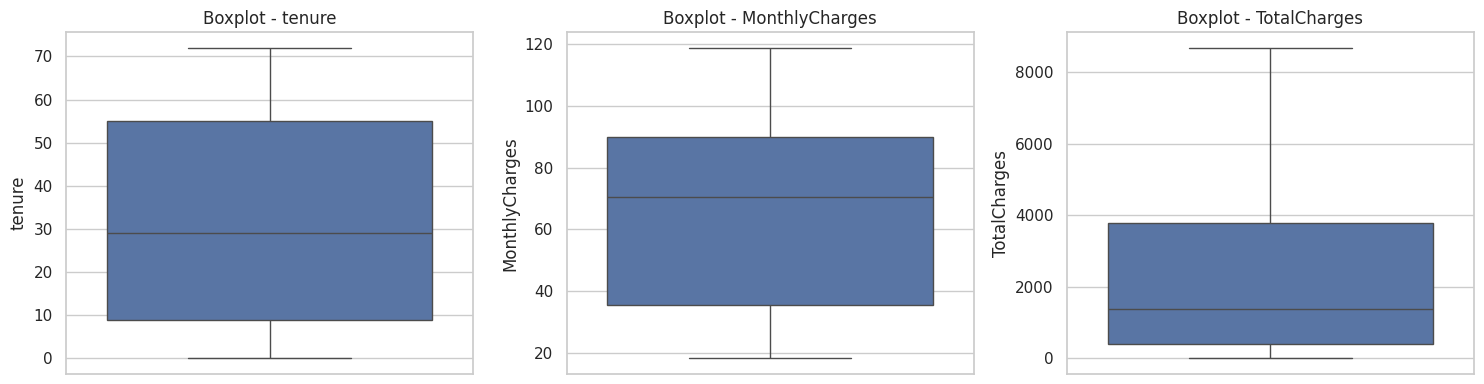

In [ ]:
cols_numericas = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, cols_numericas):
    q1 = df_analisis[col].quantile(0.25)
    q3 = df_analisis[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr

    outliers = df_analisis[(df_analisis[col] < lim_inf) | (df_analisis[col] > lim_sup)]

    print(
        f"{col}: Q1={q1:.2f}, Q3={q3:.2f}, "
        f"IQR={iqr:.2f} | Límites=[{lim_inf:.2f}, {lim_sup:.2f}] "
        f"| Outliers={len(outliers)}"
    )

    sns.boxplot(y=df_analisis[col], ax=ax)
    ax.set_title(f"Boxplot - {col}")

plt.tight_layout()
plt.show()

**Análisis y tratamiento de valores atípicos (IQR):**
Al aplicar la regla de `1.5 * IQR` sobre `tenure`, `MonthlyCharges` y `TotalCharges`, no se identifican valores atípicos (`Outliers = 0` en las tres variables), ya que todas las observaciones caen dentro de los límites inferior y superior calculados. En consecuencia, **no se eliminan ni modifican registros**, conservando la totalidad del dataset depurado.

### 4.5. Exportación del dataset procesado

In [ ]:
# 4. Guardado del dataset procesado en la carpeta de Colab
os.makedirs("data/processed", exist_ok=True)
df_analisis.to_csv("data/processed/telco_churn_limpio.csv", index=False)
print("Guardado en: data/processed/telco_churn_limpio.csv")

Guardado en: data/processed/telco_churn_limpio.csv


## 5. Análisis Exploratorio y Visualización

### 5.1. Medidas de tendencia central y dispersión

Calculamos medidas estadísticas descriptivas para las variables numéricas tenure, MonthlyCharges y TotalCharges, con el objetivo de conocer sus valores centrales y analizar la variabilidad de los datos.

In [ ]:
# Variables numéricas que vamos a analizar
cols_estadisticas = ["tenure", "MonthlyCharges", "TotalCharges"]

# Calculamos medidas de tendencia central y dispersión
estadisticas = df_analisis[cols_estadisticas].agg(
    ["mean", "median", "std", "var", "min", "max"]
).T

estadisticas.columns = [
    "Media", "Mediana", "Desvío estándar",
    "Varianza", "Mínimo", "Máximo"
]

display(estadisticas.round(2))

,Media,Mediana,Desvío estándar,Varianza,Mínimo,Máximo
tenure,32.37,29.00,24.56,603.17,0.00,72.00
MonthlyCharges,64.76,70.35,30.09,905.41,18.25,118.75
TotalCharges,2279.73,1394.55,2266.79,5138357.17,0.00,8684.80


**Interpretación:**
- Tenure: la antigüedad promedio es de 32,37 meses, mientras que la mediana es de 29 meses. Esto indica que la mitad de los clientes tiene una antigüedad igual o inferior a 29 meses y la otra mitad igual o superior. El desvío estándar de 24,56 meses refleja una dispersión considerable en el tiempo de permanencia.

- MonthlyCharges: el cargo mensual promedio es de 64,76, mientras que la mediana alcanza los 70,35. La diferencia entre ambos valores indica que existen cargos relativamente bajos que reducen el promedio. El desvío estándar de 30,09 muestra una variabilidad importante en los importes que pagan los clientes.

- TotalCharges: el promedio acumulado es de 2279,73, mientras que la mediana es de 1394,55. Esta diferencia evidencia una distribución desigual de los cargos acumulados, con algunos valores elevados que incrementan el promedio. El desvío estándar de 2266,79 confirma una dispersión considerable.

Conclusión general: las tres variables presentan diferencias entre sus valores centrales y una dispersión apreciable. Esto refleja que los clientes tienen distintas antigüedades y niveles de facturación, por lo que resulta conveniente profundizar el análisis mediante las correlaciones y visualizaciones posteriores.

### 5.2. Correlación de Pearson entre variables numéricas
Evaluamos la relación lineal entre `tenure`, `MonthlyCharges` y `TotalCharges` mediante el coeficiente de correlación de Pearson y su mapa de calor.


,tenure,MonthlyCharges,TotalCharges
tenure,1.0000,0.2479,0.8262
MonthlyCharges,0.2479,1.0000,0.6512
TotalCharges,0.8262,0.6512,1.0000


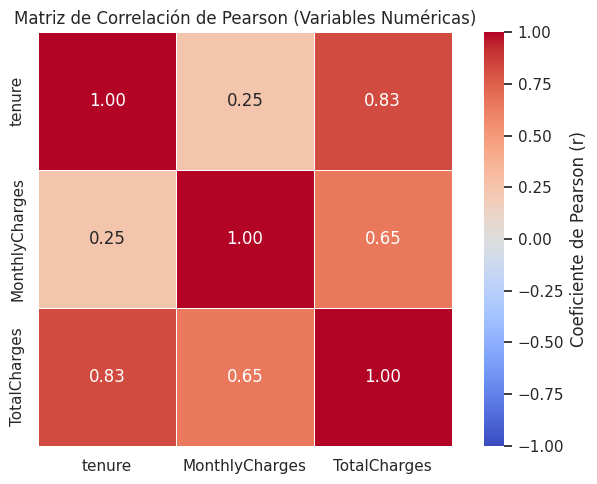

In [ ]:
# Matriz de correlación de Pearson entre variables numéricas clave
cols_corr = ["tenure", "MonthlyCharges", "TotalCharges"]
corr_pearson = df_analisis[cols_corr].corr(method="pearson")

display(corr_pearson.round(4))

# Heatmap de la matriz de correlación
plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Coeficiente de Pearson (r)"}
)
plt.title("Matriz de Correlación de Pearson (Variables Numéricas)")
plt.tight_layout()
plt.show()

**Interpretación:**
Se observa una correlación lineal positiva fuerte entre `tenure` y `TotalCharges` ($r \approx 0,83$), ya que a mayor antigüedad mayor es el monto acumulado. Entre `MonthlyCharges` y `TotalCharges` existe una correlación positiva moderada-alta ($r \approx 0,65$), mientras que `tenure` y `MonthlyCharges` presentan una relación débil ($r \approx 0,25$). Para el negocio, esto indica que retener clientes por más tiempo es clave para maximizar el ingreso acumulado, independientemente del cargo mensual.

### **5.3**. Distribución de antigüedad y cargos mensuales
Analizamos la distribución de `tenure` y `MonthlyCharges` mediante histogramas con curva KDE.

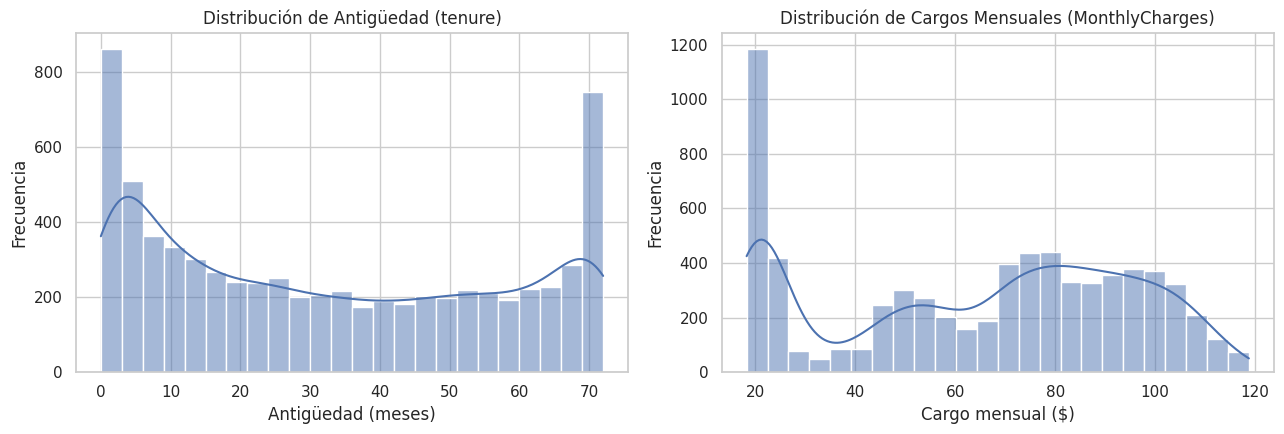

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df_analisis["tenure"], kde=True, bins=24, ax=axes[0])
axes[0].set_title("Distribución de Antigüedad (tenure)")
axes[0].set_xlabel("Antigüedad (meses)")
axes[0].set_ylabel("Frecuencia")

sns.histplot(df_analisis["MonthlyCharges"], kde=True, bins=24, ax=axes[1])
axes[1].set_title("Distribución de Cargos Mensuales (MonthlyCharges)")
axes[1].set_xlabel("Cargo mensual ($)")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

Interpretación: En tenure se observa una distribución bimodal, con una alta concentración de clientes recientes (primeros meses) y otro grupo fuerte en torno a los 70–72 meses de antigüedad, lo que sugiere que los primeros meses son críticos para la retención. En MonthlyCharges destaca un pico marcado cerca de los USD 20 (planes más básicos) y un segundo tramo amplio entre USD 70 y USD 105 (planes con mayor cantidad de servicios).

### **5.4**. Tasa de cancelación según tipo de contrato y método de pago
Comparamos la proporción de clientes que cancelan (`Cancelacion == "Yes"`) según `Contract` y `PaymentMethod`.

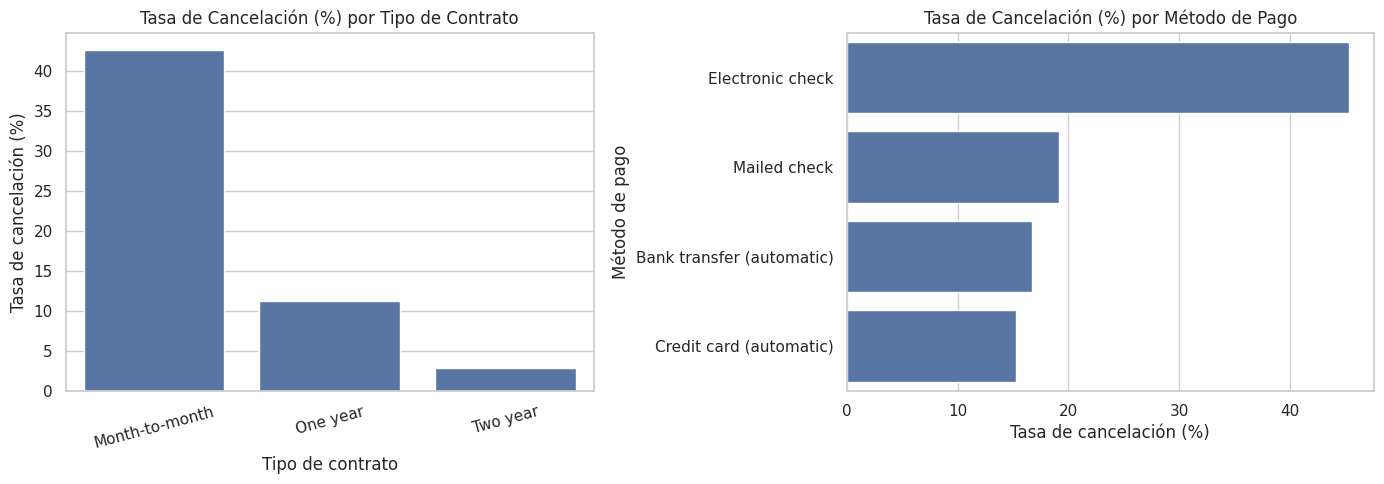

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tasa de Churn (%) por tipo de contrato
churn_contrato = (
    df_analisis.groupby("Contract")["Cancelacion"]
    .apply(lambda s: (s == "Yes").mean() * 100)
    .reset_index(name="Tasa_Churn_Pct")
)
sns.barplot(data=churn_contrato, x="Contract", y="Tasa_Churn_Pct", ax=axes[0])
axes[0].set_title("Tasa de Cancelación (%) por Tipo de Contrato")
axes[0].set_xlabel("Tipo de contrato")
axes[0].set_ylabel("Tasa de cancelación (%)")
axes[0].tick_params(axis="x", rotation=15)

# Tasa de Churn (%) por método de pago
churn_pago = (
    df_analisis.groupby("PaymentMethod")["Cancelacion"]
    .apply(lambda s: (s == "Yes").mean() * 100)
    .sort_values(ascending=False)
    .reset_index(name="Tasa_Churn_Pct")
)
sns.barplot(data=churn_pago, y="PaymentMethod", x="Tasa_Churn_Pct", ax=axes[1])
axes[1].set_title("Tasa de Cancelación (%) por Método de Pago")
axes[1].set_xlabel("Tasa de cancelación (%)")
axes[1].set_ylabel("Método de pago")

plt.tight_layout()
plt.show()

**Interpretación:**
Los contratos `Month-to-month` presentan una tasa de cancelación muy superior (por encima del 40%) frente a los contratos anuales o bianuales, donde la permanencia reduce drásticamente el *churn*. Asimismo, `Electronic check` registra la mayor proporción de bajas (más del 45%), mientras que los medios de pago automáticos muestran tasas considerablemente menores. A nivel de negocio, incentivar contratos de mayor plazo y migración a débito/pago automático son palancas directas para reducir la cancelación.

### 5.5. Tabla de contingencia y resumen de cancelación
Revisamos la distribución conjunta de las variables categóricas clave (SeniorCitizen y Contract) frente a Cancelacion, junto con la tasa global de cancelación del dataset, con el objetivo de contrastar las hipótesis planteadas al inicio del estudio.

In [ ]:
def resumen_contingencia(df, columna, etiquetas_indice=None):
    # Frecuencias absolutas y porcentajes por fila
    abs_df = pd.crosstab(df[columna], df["Cancelacion"])
    pct_df = pd.crosstab(df[columna], df["Cancelacion"], normalize="index") * 100

    # Combinamos ambos en una sola tabla limpia
    resumen = pd.DataFrame({
        "Continúan (No)": abs_df["No"],
        "Cancelaron (Yes)": abs_df["Yes"],
        "Total Clientes": abs_df.sum(axis=1),
        "Tasa de Churn (%)": pct_df["Yes"].round(2)
    })

    if etiquetas_indice:
        resumen.index = resumen.index.map(etiquetas_indice)
    resumen.index.name = columna
    return resumen

print(f"Tasa global de cancelación (Churn): {(df_analisis['Cancelacion'] == 'Yes').mean() * 100:.2f}%\n")

print("=== Resumen por Condición de Adulto Mayor (SeniorCitizen) ===")
display(resumen_contingencia(df_analisis, "SeniorCitizen", {0: "No (0)", 1: "Sí (1)"}))

print("\n=== Resumen por Tipo de Contrato (Contract) ===")
display(resumen_contingencia(df_analisis, "Contract"))

Tasa global de cancelación (Churn): 26.54%

=== Resumen por Condición de Adulto Mayor (SeniorCitizen) ===


,Continúan (No),Cancelaron (Yes),Total Clientes,Tasa de Churn (%)
SeniorCitizen,,,,
No (0),4508,1393,5901,23.61
Sí (1),666,476,1142,41.68



=== Resumen por Tipo de Contrato (Contract) ===


,Continúan (No),Cancelaron (Yes),Total Clientes,Tasa de Churn (%)
Contract,,,,
Month-to-month,2220,1655,3875,42.71
One year,1307,166,1473,11.27
Two year,1647,48,1695,2.83


**Interpretación:**
Interpretación:
La tasa global de cancelación del dataset es del 26,54% (1.869 bajas sobre 7.043 clientes), pero presenta diferencias marcadas al desagregar por perfil demográfico y contractual:

Condición de adulto mayor (SeniorCitizen): Los adultos mayores (1) registran una tasa de cancelación del 41,68% (476 bajas), casi duplicando el 23,61% observado en usuarios más jóvenes (0). Esto confirma la Hipótesis 1.

Tipo de contrato (Contract): La cancelación se concentra fuertemente en los contratos Month-to-month (42,71%, con 1.655 bajas), frente al 11,27% en contratos anuales y apenas 2,83% en los de dos años. Esto demuestra que la ausencia de compromiso contractual de largo plazo es uno de los factores más asociados a la pérdida de clientes, confirmando la Hipótesis 2.

## 6. Conclusiones y Recomendaciones de Negocio

### Conclusiones principales del análisis
- **Calidad de datos y coherencia de facturación:** `TotalCharges` presentaba cadenas vacías asociadas a clientes de muy baja antigüedad (`tenure` cercano a 0), que se imputaron de forma consistente (`0.0`) y se convirtieron a `float64` sin pérdida de registros. Al contrastar `TotalCharges` con `Cargo_Esperado` (`tenure * MonthlyCharges`) y analizar *outliers* mediante IQR, se verificó que los valores extremos corresponden a perfiles reales del negocio (por ejemplo, planes más cargados o clientes de larga trayectoria), por lo que conservarlos preserva la fidelidad de la muestra.
- **Relaciones numéricas:** Se observa una correlación positiva fuerte entre `tenure` y `TotalCharges` (a mayor permanencia acumulada, mayor facturación total histórica), mientras que la relación entre `MonthlyCharges` y `tenure` es moderada/débil, lo que indica que el precio mensual del plan no depende linealmente de la antigüedad del cliente.
- **Antigüedad y estructura de cargos:** La distribución de `tenure` muestra un peso importante de clientes en sus primeros meses (ventana crítica de fuga) junto a un núcleo consolidado de larga antigüedad. En `MonthlyCharges` se distingue un bloque de entrada alrededor de USD 20 y otro más amplio entre USD 70 y USD 105, concentrando mayor presión de gasto mensual en planes más completos.
- **Impacto de la condición de adulto mayor (`SeniorCitizen`):** Al evaluar la variable sociodemográfica `SeniorCitizen`, se comprobó que los adultos mayores (`SeniorCitizen = 1`) presentan una tasa de cancelación del **41,68%** (476 bajas), casi duplicando el **23,61%** registrado en los clientes más jóvenes, lo que confirma una mayor propensión al abandono en este segmento.
- **Riesgo de cancelación por contrato y método de pago:** Los contratos `Month-to-month` concentran una tasa de cancelación sensiblemente superior frente a los contratos de uno o dos años, donde la permanencia pactada reduce el abandono. Asimismo, ciertos métodos de pago (como `Electronic check`) muestran mayor rotación frente a medios automáticos o recurrentes, reforzando el segmento de riesgo identificado en `clientes_riesgo`.

### Recomendaciones estratégicas
1. **Programa de retención en los primeros meses (*onboarding* y seguimiento temprano):** Enfocar acciones de soporte, beneficios iniciales o revisiones de plan durante los primeros 3 a 6 meses de `tenure`, cuando el cliente aún no construyó hábito ni compromiso de largo plazo.
2. **Migración incentivada de `Month-to-month` hacia planes anuales:** Ofrecer descuentos escalonados, bonificaciones en meses seleccionados o mejoras de velocidad/servicios al pasar de contrato mensual a anual, priorizando clientes con `MonthlyCharges` elevados.
3. **Fomento del débito automático / medios de pago recurrentes:** Promover el cambio desde pago manual o `Electronic check` hacia débito automático mediante pequeños incentivos o mayor previsibilidad en la facturación, reduciendo fricciones y olvidos de pago.
4. **Monitoreo segmentado del grupo de alto riesgo (`clientes_riesgo` y `SeniorCitizen`):** Utilizar el segmento filtrado (contratos mensuales, cargos altos o adultos mayores combinados con cancelación/riesgo) para campañas preventivas focalizadas y atención personalizada, midiendo el impacto en la tasa global de *Churn* tras aplicar las medidas.